# 02 - Feature engineering

**Goal of this notebook:** turn the clean table into a numeric matrix that K-Means can use.

Steps:
1. Filter out players with too little playing time.
2. Choose the features that describe *how* a player plays.
3. Check that the chosen features have no missing values.
4. Scale the features so they all weigh the same in a distance.

**Input:** `data/processed/players_per36_clean.csv`
**Output:** `data/processed/players_features.csv` (real units) and `data/processed/players_scaled.csv` (scaled)

## 1. Imports and settings

`NumPy` is the library for numeric arrays; pandas is built on top of it. `StandardScaler` comes from `scikit-learn`, the machine learning library we will use for the rest of the project.

The three constants below are the decisions of this notebook. Changing them and re-running everything is how we will test how sensitive the results are.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

INPUT_PATH = Path("../data/processed/players_per36_clean.csv")
FEATURES_PATH = Path("../data/processed/players_features.csv")
SCALED_PATH = Path("../data/processed/players_scaled.csv")

MIN_TOTAL_MINUTES = 700
MIN_MINUTES_PER_GAME = 15

FEATURES = [
    "fg2a_per36",
    "fg3a_per36",
    "fta_per36",
    "orb_per36",
    "drb_per36",
    "ast_per36",
    "stl_per36",
    "blk_per36",
    "tov_per36",
]

# Columns we keep aside to identify players. They are NOT used for clustering.
META_COLUMNS = ["player_id", "player", "team", "position", "games", "minutes_per_game"]

## 2. Load

Same table that notebook 01 saved.

In [2]:
df = pd.read_csv(INPUT_PATH)
df.shape

(582, 30)

## 3. Filter by playing time

Per-36 numbers are unreliable when a player barely played, so we ask for two things:

- **Enough total minutes** (`MIN_TOTAL_MINUTES`): a big enough sample for the per-36 numbers to be trustworthy. We use total minutes and not number of games on purpose: a star who missed half the season through injury still played plenty of minutes, and his per-36 numbers are reliable.
- **Enough minutes per game** (`MIN_MINUTES_PER_GAME`): the player has a real role, not just garbage-time appearances.

Minutes per game is not in the table, but we can compute it from two columns we already have.

In [3]:
df["minutes_per_game"] = df["minutes_total"] / df["games"]
df[["player", "games", "minutes_total", "minutes_per_game"]].head()

,player,games,minutes_total,minutes_per_game
0,Amen Thompson,79,2953,37.379747
1,Kevin Durant,78,2840,36.410256
2,Desmond Bane,82,2756,33.609756
3,Toumani Camara,82,2731,33.304878
4,Jabari Smith Jr.,77,2705,35.129870


`(df["minutes_total"] >= MIN_TOTAL_MINUTES) & (df["minutes_per_game"] >= MIN_MINUTES_PER_GAME)` builds a True/False value for each player. `&` means "and", and each condition needs its own parentheses. Using it to index the DataFrame keeps only the `True` rows.

In [4]:
enough_playing_time = (df["minutes_total"] >= MIN_TOTAL_MINUTES) & (df["minutes_per_game"] >= MIN_MINUTES_PER_GAME)
enough_playing_time.sum()

np.int64(325)

In [5]:
df_kept = df[enough_playing_time].reset_index(drop=True)
df_kept.shape

(325, 31)

Who did we lose? The removed players with the most total minutes show the cost of the filter. Check whether any of them is someone you would expect in the analysis: that is the question to ask every time we change a threshold.

In [6]:
df[~enough_playing_time].sort_values("minutes_total", ascending=False).head(8)[
    ["player", "position", "games", "minutes_per_game", "minutes_total"]
]

,player,position,games,minutes_per_game,minutes_total
263,Hugo González,SF,74,14.648649,1084
268,Gradey Dick,SG,76,14.039474,1067
281,Tyus Jones,PG,67,14.611940,979
285,Rob Dillingham,PG,65,14.923077,970
293,Clint Capela,C,75,12.346667,926
295,Micah Peavy,SG,61,14.967213,913
296,Karlo Matković,PF,62,14.709677,912
301,Dwight Powell,C,63,14.349206,904


Is the sample still balanced across positions? If one position had almost disappeared, the final comparison would be unfair.

In [7]:
df_kept["position"].value_counts()

position
SG    88
PF    62
SF    59
PG    58
C     58
Name: count, dtype: int64

## 4. Choose the features

We want features about **volume of play style** (how much a player shoots from where, rebounds, passes, steals, blocks), not about **quality** (shooting percentages), and we leave out columns that are sums of others (`pts`, `trb`, `fga`) so the same information is not counted twice.

Let's select them and make sure there are no missing values. The percentage columns were the ones with nulls, and none of them is in the list.

In [8]:
df_features = df_kept[FEATURES]
df_features.isna().sum()

fg2a_per36    0
fg3a_per36    0
fta_per36     0
orb_per36     0
drb_per36     0
ast_per36     0
stl_per36     0
blk_per36     0
tov_per36     0
dtype: int64

In [9]:
df_features.describe().round(2)

,fg2a_per36,fg3a_per36,fta_per36,orb_per36,drb_per36,ast_per36,stl_per36,blk_per36,tov_per36
count,325.00,325.00,325.00,325.00,325.00,325.00,325.00,325.00,325.00
mean,7.69,5.55,3.47,1.71,4.79,3.97,1.26,0.72,2.05
std,3.25,2.68,1.99,1.26,1.80,2.00,0.44,0.59,0.77
min,0.30,0.00,0.30,0.20,1.50,0.90,0.40,0.10,0.40
25%,5.10,4.10,2.00,0.80,3.50,2.40,0.90,0.30,1.50
50%,7.50,5.80,3.10,1.30,4.50,3.50,1.20,0.50,1.90
75%,9.80,7.40,4.40,2.20,5.70,5.00,1.50,0.90,2.50
max,19.20,13.20,12.40,7.70,11.70,11.10,3.20,3.80,4.10


Look at the `mean` and `std` rows: `fg2a_per36` and `drb_per36` live around 5-8, `stl_per36` around 1. Without scaling, K-Means would pay much more attention to the first ones.

## 5. How related are the features?

The correlation goes from -1 to 1: close to 1 means two columns move together, close to -1 means they move in opposite directions, close to 0 means they are unrelated.

In [10]:
corr = df_features.corr()
corr.round(2)

,fg2a_per36,fg3a_per36,fta_per36,orb_per36,drb_per36,ast_per36,stl_per36,blk_per36,tov_per36
fg2a_per36,1.00,-0.28,0.77,0.14,0.35,0.36,-0.04,0.13,0.58
fg3a_per36,-0.28,1.00,-0.09,-0.67,-0.39,0.09,-0.06,-0.41,0.10
fta_per36,0.77,-0.09,1.00,0.03,0.27,0.31,-0.09,0.06,0.58
orb_per36,0.14,-0.67,0.03,1.00,0.64,-0.31,-0.00,0.59,-0.16
drb_per36,0.35,-0.39,0.27,0.64,1.00,-0.06,-0.09,0.55,0.17
ast_per36,0.36,0.09,0.31,-0.31,-0.06,1.00,0.19,-0.29,0.70
stl_per36,-0.04,-0.06,-0.09,-0.00,-0.09,0.19,1.00,-0.07,0.08
blk_per36,0.13,-0.41,0.06,0.59,0.55,-0.29,-0.07,1.00,-0.10
tov_per36,0.58,0.10,0.58,-0.16,0.17,0.70,0.08,-0.10,1.00


Text(0.5, 1.0, 'Correlation between features')

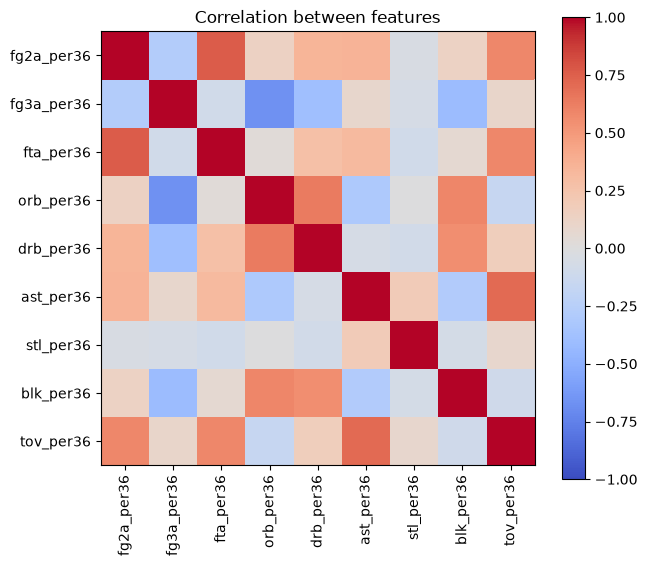

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im)
ax.set_title("Correlation between features")

The highest values are `fta_per36` with `fg2a_per36` (about 0.77) and `ast_per36` with `tov_per36` (about 0.70). Both make basketball sense: players who attack the rim get fouled, and players who handle the ball turn it over. They are related but not duplicates, and far from the correlation between a sum and one of its parts (like `trb` and `drb`, above 0.9), so we keep all 9 features.

## 6. Scale

`StandardScaler` replaces every value by `z = (value - column mean) / column std`. After that, each column has mean 0 and standard deviation 1, and a difference of 1 means the same thing in every column.

It works in two steps, which is the pattern of almost every scikit-learn tool: `fit` learns the mean and std of each column, and `transform` applies the formula. `fit_transform` does both at once.

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_features)
type(X_scaled), X_scaled.shape

(numpy.ndarray, (325, 9))

The result is a NumPy array, not a DataFrame: it lost the column names and the index. Let's put them back.

In [13]:
df_scaled_features = pd.DataFrame(X_scaled, columns=FEATURES, index=df_features.index)
df_scaled_features.head()

,fg2a_per36,fg3a_per36,fta_per36,orb_per36,drb_per36,ast_per36,stl_per36,blk_per36,tov_per36
0,1.110109,-1.547166,0.668746,0.951286,-0.106838,0.567183,0.544945,-0.209062,0.331116
1,1.233212,0.057647,1.222676,-0.961093,0.060364,0.367091,-1.050615,0.299256,1.377167
2,0.771574,0.020326,0.517674,-0.323633,-0.942848,0.217023,-0.366803,-0.378501,0.069603
3,-1.167305,0.841393,-0.841975,-0.004904,-0.552710,-0.683390,-0.138866,-0.378501,-0.191910
4,-0.367132,0.356217,-0.338401,-0.243951,0.450502,-1.033551,-1.278552,0.299256,-0.845692


Check 1: every column should have mean 0 and std 1. (`StandardScaler` divides by *n*, so we ask pandas to do the same with `ddof=0`.)

In [14]:
pd.DataFrame({
    "mean": df_scaled_features.mean(),
    "std": df_scaled_features.std(ddof=0),
}).round(3)

,mean,std
fg2a_per36,0.0,1.0
fg3a_per36,0.0,1.0
fta_per36,-0.0,1.0
orb_per36,0.0,1.0
drb_per36,-0.0,1.0
ast_per36,-0.0,1.0
stl_per36,-0.0,1.0
blk_per36,-0.0,1.0
tov_per36,-0.0,1.0


Check 2: the same formula we computed by hand in the exercise should give identical numbers. `np.allclose` compares two tables of decimals ignoring tiny rounding differences.

In [15]:
manual = (df_features - df_features.mean()) / df_features.std(ddof=0)
np.allclose(manual, df_scaled_features)

True

Check 3: a known player. Positive means above the average of the kept players, negative means below.

In [16]:
df_scaled_features[df_kept["player"].isin(["Nikola Jokić", "Luka Dončić"])].round(2).assign(
    player=df_kept["player"]
)

,fg2a_per36,fg3a_per36,fta_per36,orb_per36,drb_per36,ast_per36,stl_per36,blk_per36,tov_per36,player
36,1.33,2.00,3.34,-0.88,1.29,2.17,1.00,-0.38,2.55,Luka Dončić
42,1.73,-0.32,2.08,1.11,3.01,3.57,0.54,0.13,2.42,Nikola Jokić


## 7. Save

We save two files. The scaled one is what K-Means will read. The one in real units is for the end of the project, when we describe each cluster in numbers we understand (assists per 36, not z-scores). Both keep the identification columns next to the features, but those columns are never used to cluster.

In [17]:
players_features = pd.concat([df_kept[META_COLUMNS], df_features], axis=1)
players_scaled = pd.concat([df_kept[META_COLUMNS], df_scaled_features], axis=1)

players_features.to_csv(FEATURES_PATH, index=False)
players_scaled.to_csv(SCALED_PATH, index=False)
players_scaled.shape

(325, 15)

## Summary

- Kept players with at least 700 total minutes and 15 minutes per game (325 players), with the five positions still well represented. Filtering by total minutes instead of games keeps injured stars whose per-36 numbers are reliable.
- 9 features about play style (volume of 2-point attempts, 3-point attempts, free throws, offensive and defensive rebounds, assists, steals, blocks and turnovers).
- No missing values, and no feature is a sum of others.
- Features scaled to mean 0 and std 1; real-unit and scaled versions saved.
- Next: K-Means for several values of k, and how to choose k.